In [1]:
print("hello world")

hello world


In [ ]:
import numpy as np
import pandas as pd
from datasets import load_dataset
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import Embedding, Conv1D, GlobalMaxPooling1D, Dropout, Dense, Concatenate, Input
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow as tf
import os


In [ ]:

# Set cache directory for datasets
cache_dir = "./liar_cache"
os.makedirs(cache_dir, exist_ok=True)
os.environ['HF_DATASETS_CACHE'] = cache_dir

# 1. Load the LIAR dataset
try:
    dataset = load_dataset("ucsbnlp/liar", cache_dir=cache_dir, trust_remote_code=True)
    train_data = dataset['train']
    valid_data = dataset['validation']
    test_data = dataset['test']
except Exception as e:
    print(f"Error loading dataset: {e}")
    raise

# Extract statements and labels
train_texts = [item['statement'] for item in train_data]
train_labels = [item['label'] for item in train_data]
valid_texts = [item['statement'] for item in valid_data]
valid_labels = [item['label'] for item in valid_data]
test_texts = [item['statement'] for item in test_data]
test_labels = [item['label'] for item in test_data]

print("First few train labels:", train_labels[:5])
print("First few valid labels:", valid_labels[:5])
print("First few test labels:", test_labels[:5])

First few train labels: [0, 1, 2, 0, 1]
First few valid labels: [4, 5, 0, 1, 1]
First few test labels: [3, 0, 0, 1, 5]


In [ ]:
# Label encoding
label_map = {'pants-fire': 0, 'false': 1, 'barely-true': 2, 'half-true': 3, 'mostly-true': 4, 'true': 5}
if isinstance(train_labels[0], str):
    train_labels = [label_map[label] for label in train_labels]
    valid_labels = [label_map[label] for label in valid_labels]
    test_labels = [label_map[label] for label in test_labels]
else:
    # Verify integer labels are in range [0, 5]
    for labels, name in [(train_labels, "train"), (valid_labels, "valid"), (test_labels, "test")]:
        if any(not isinstance(label, (int, np.integer)) or label < 0 or label > 5 for label in labels):
            raise ValueError(f"Invalid integer labels in {name} set: must be in range [0, 5]")

# Convert labels to one-hot encoded format
train_labels = to_categorical(train_labels, num_classes=6)
valid_labels = to_categorical(valid_labels, num_classes=6)
test_labels = to_categorical(test_labels, num_classes=6)

In [ ]:

# 2. Data Preprocessing
max_words = 100000  # Vocabulary size
max_len = 100  # Maximum sequence length

# Tokenization
tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
tokenizer.fit_on_texts(train_texts)

# Convert texts to sequences
train_sequences = tokenizer.texts_to_sequences(train_texts)
valid_sequences = tokenizer.texts_to_sequences(valid_texts)
test_sequences = tokenizer.texts_to_sequences(test_texts)

# Pad sequences
train_padded = pad_sequences(train_sequences, maxlen=max_len, padding='post', truncating='post')
valid_padded = pad_sequences(valid_sequences, maxlen=max_len, padding='post', truncating='post')
test_padded = pad_sequences(test_sequences, maxlen=max_len, padding='post', truncating='post')

# 3. Load GloVe Embeddings
def load_glove_embeddings(glove_file_path, word_index, embedding_dim=100):
    embeddings_index = {}
    with open(glove_file_path, encoding='utf-8') as f:
        for line in f:
            values = line.split()
            word = values[0]
            coefs = np.asarray(values[1:], dtype='float32')
            embeddings_index[word] = coefs
    
    embedding_matrix = np.zeros((max_words, embedding_dim))
    for word, i in word_index.items():
        if i < max_words:
            embedding_vector = embeddings_index.get(word)
            if embedding_vector is not None:
                embedding_matrix[i] = embedding_vector
    
    return embedding_matrix

# Specify path to GloVe file
glove_file_path = '../CNN/glove.6B.100d.txt'  # Update this path based on your local setup
embedding_matrix = load_glove_embeddings(glove_file_path, tokenizer.word_index)


In [ ]:

# 4. Build TextCNN Model
def build_textcnn_model(vocab_size, embedding_dim, max_len, embedding_matrix):
    input_layer = Input(shape=(max_len,))
    
    # Embedding Layer
    embedding_layer = Embedding(vocab_size, embedding_dim, weights=[embedding_matrix], 
                              input_length=max_len, trainable=False)(input_layer)
    
    # Convolutional Layers with different kernel sizes
    convs = []
    filter_sizes = [2, 3, 4]
    
    for filter_size in filter_sizes:
        conv = Conv1D(filters=128, kernel_size=filter_size, activation='relu')(embedding_layer)
        pool = GlobalMaxPooling1D()(conv)
        convs.append(pool)
    
    # Concatenate Layer
    concatenated = Concatenate()(convs)
    
    # Dense Layers
    dense = Dense(50, activation='relu')(concatenated)
    dropout = Dropout(0.1)(dense)
    
    # Output Layer
    output = Dense(6, activation='softmax')(dropout)
    
    model = tf.keras.Model(inputs=input_layer, outputs=output)
    return model

# Initialize and compile the model
embedding_dim = 100
model = build_textcnn_model(max_words, embedding_dim, max_len, embedding_matrix)
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Model summary
model.summary()

# 5. Training Setup
early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# Train the model
history = model.fit(
    train_padded, train_labels,
    epochs=6,
    batch_size=128,
    validation_data=(valid_padded, valid_labels),
    callbacks=[early_stopping]
)




Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_9       │ (None, 100)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_9         │ (None, 100, 100)  │ 10,000,000 │ input_layer_9[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_27 (Conv1D)  │ (None, 99, 128)   │     25,728 │ embedding_9[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_28 (Conv1D)  │ (None, 98, 128)   │     38,528 │ embedding_9[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_29 (Conv1D)  │ (None, 97, 128)   │     51,328 │ embedding_9[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ conv1d_27[0][0]   │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ conv1d_28[0][0]   │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ conv1d_29[0][0]   │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_9       │ (None, 384)       │          0 │ global_max_pooli… │
│ (Concatenate)       │                   │            │ global_max_pooli… │
│                     │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_18 (Dense)    │ (None, 50)        │     19,250 │ concatenate_9[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_9 (Dropout) │ (None, 50)        │          0 │ dense_18[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_19 (Dense)    │ (None, 6)         │        306 │ dropout_9[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 10,135,140 (38.66 MB)

 Trainable params: 135,140 (527.89 KB)

 Non-trainable params: 10,000,000 (38.15 MB)

Epoch 1/6
81/81 ━━━━━━━━━━━━━━━━━━━━ 15s 102ms/step - accuracy: 0.1913 - loss: 1.8189 - val_accuracy: 0.2383 - val_loss: 1.7493
Epoch 2/6
81/81 ━━━━━━━━━━━━━━━━━━━━ 8s 95ms/step - accuracy: 0.2582 - loss: 1.7125 - val_accuracy: 0.2484 - val_loss: 1.7162
Epoch 3/6
81/81 ━━━━━━━━━━━━━━━━━━━━ 8s 96ms/step - accuracy: 0.2999 - loss: 1.6565 - val_accuracy: 0.2586 - val_loss: 1.7232
Epoch 4/6
81/81 ━━━━━━━━━━━━━━━━━━━━ 8s 94ms/step - accuracy: 0.3237 - loss: 1.6060 - val_accuracy: 0.2617 - val_loss: 1.6998
Epoch 5/6
81/81 ━━━━━━━━━━━━━━━━━━━━ 8s 96ms/step - accuracy: 0.3619 - loss: 1.5382 - val_accuracy: 0.2562 - val_loss: 1.7015
Epoch 6/6
81/81 ━━━━━━━━━━━━━━━━━━━━ 8s 94ms/step - accuracy: 0.4306 - loss: 1.4323 - val_accuracy: 0.2570 - val_loss: 1.7365


In [ ]:
# 6. Evaluate the model
test_loss, test_accuracy = model.evaluate(test_padded, test_labels)
print(f"Test Accuracy: {test_accuracy:.4f}")

41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.2519 - loss: 1.7277
Test Accuracy: 0.2564


In [ ]:
# 6. Evaluate the model
# Define Top-3 Accuracy function
def top_k_accuracy(y_true, y_pred, k=3):
    top_k = tf.math.top_k(y_pred, k=k)[1]  # Get indices of top-k predictions
    y_true_indices = tf.argmax(y_true, axis=1)  # Get true label indices
    correct = tf.reduce_any(tf.equal(tf.cast(top_k, tf.int64), tf.expand_dims(y_true_indices, axis=-1)), axis=-1)
    return tf.reduce_mean(tf.cast(correct, tf.float32))

# Get predictions
y_pred_proba = model.predict(test_padded)  # Predicted probabilities
y_pred = np.argmax(y_pred_proba, axis=1)   # Predicted class indices
y_true = np.argmax(test_labels, axis=1)    # True class indices

# 7. Save the model
model.save('textcnn_liar_model.h5')

41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


Result Visualization

In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns


ModuleNotFoundError: No module named 'numpy.strings'

First few train labels: [0, 1, 2, 0, 1]
First few valid labels: [4, 5, 0, 1, 1]
First few test labels: [3, 0, 0, 1, 5]


In [ ]:

# 6. Evaluate the model
# Define Top-k Accuracy function
def top_k_accuracy(y_true, y_pred, k=3):
    top_k = tf.math.top_k(y_pred, k=k)[1]  # Get indices of top-k predictions
    y_true_indices = tf.argmax(y_true, axis=1)  # Get true label indices
    correct = tf.reduce_any(tf.equal(tf.cast(top_k, tf.int64), tf.expand_dims(y_true_indices, axis=-1)), axis=-1)
    return tf.reduce_mean(tf.cast(correct, tf.float32))

# Get predictions
y_pred_proba = model.predict(test_padded)  # Predicted probabilities
y_pred = np.argmax(y_pred_proba, axis=1)   # Predicted class indices
y_true = np.argmax(test_labels, axis=1)    # True class indices

# Compute basic metrics
test_loss, test_accuracy = model.evaluate(test_padded, test_labels, verbose=0)
test_top3_accuracy = top_k_accuracy(test_labels, y_pred_proba, k=3).numpy()

# Compute sklearn metrics
test_precision = precision_score(y_true, y_pred, average='weighted')
test_recall = recall_score(y_true, y_pred, average='weighted')
test_f1 = f1_score(y_true, y_pred, average='weighted')
test_auc = roc_auc_score(test_labels, y_pred_proba, multi_class='ovr', average='weighted')

# Print basic metrics
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Top-3 Accuracy: {test_top3_accuracy:.4f}")
print(f"Test Precision (weighted): {test_precision:.4f}")
print(f"Test Recall (weighted): {test_recall:.4f}")
print(f"Test F1 Score (weighted): {test_f1:.4f}")
print(f"Test AUC (OVR, weighted): {test_auc:.4f}")

# Compute and print classification report
label_names = ['pants-fire', 'false', 'barely-true', 'half-true', 'mostly-true', 'true']
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=label_names))

# Compute and plot confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

In [ ]:

import matplotlib.pyplot as plt


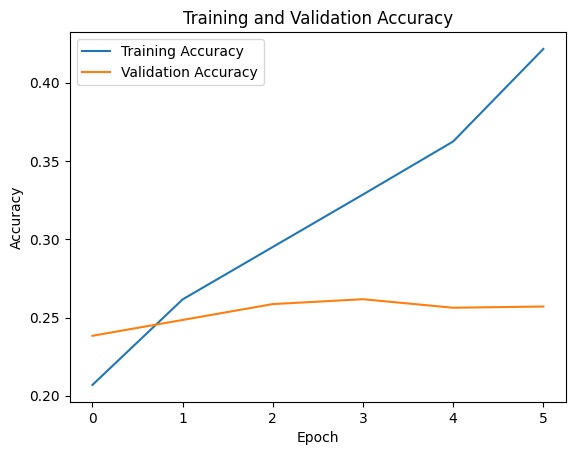

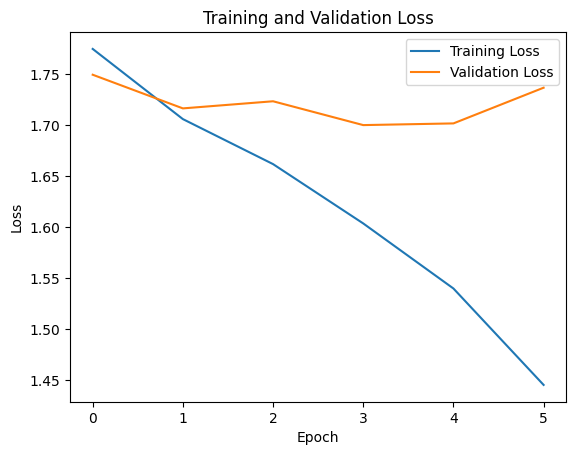

In [ ]:

# Plot accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Plot loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()